# Tutorial Topic 03 Set 01

## Prepare these Exercises before Class

In [21]:
library(tidyverse)  # for plotting, includes ggplot
library(patchwork)  # for combining multiple plots into subfigures
library(scales)     # for formatting axis scales
library(ggokabeito) # color blind friendly color palette -- this course's default

In [22]:
housing <- read_csv("data/melbourne_housing.csv")

Rows: 25698 Columns: 21
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (8): suburb, address, type, method, seller_g, date, council_area, regio...
dbl (13): rooms, price, distance, postcode, bedroom2, bathroom, car, landsiz...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


### Exercise 1

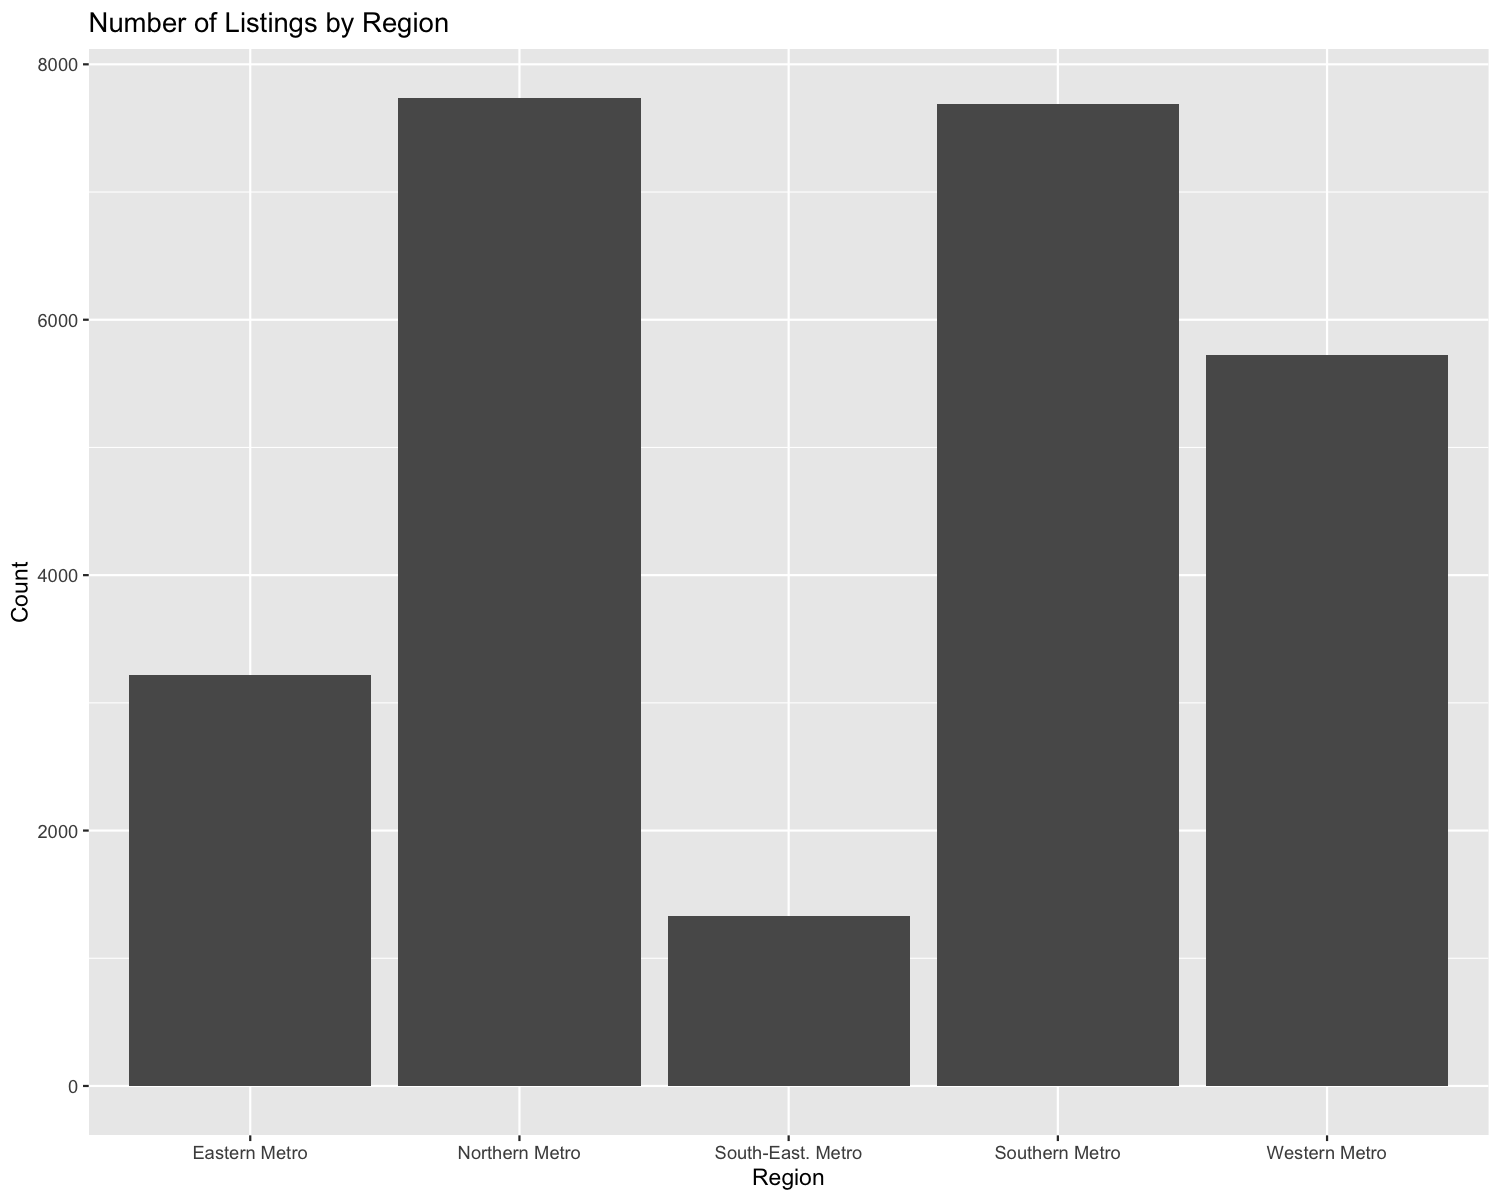

In [23]:
ggplot(housing, aes(x = regionname)) +
  geom_bar() +
  labs(
    x = "Region",
    y = "Count",
    title = "Number of Listings by Region"
  )

### Exercise 2

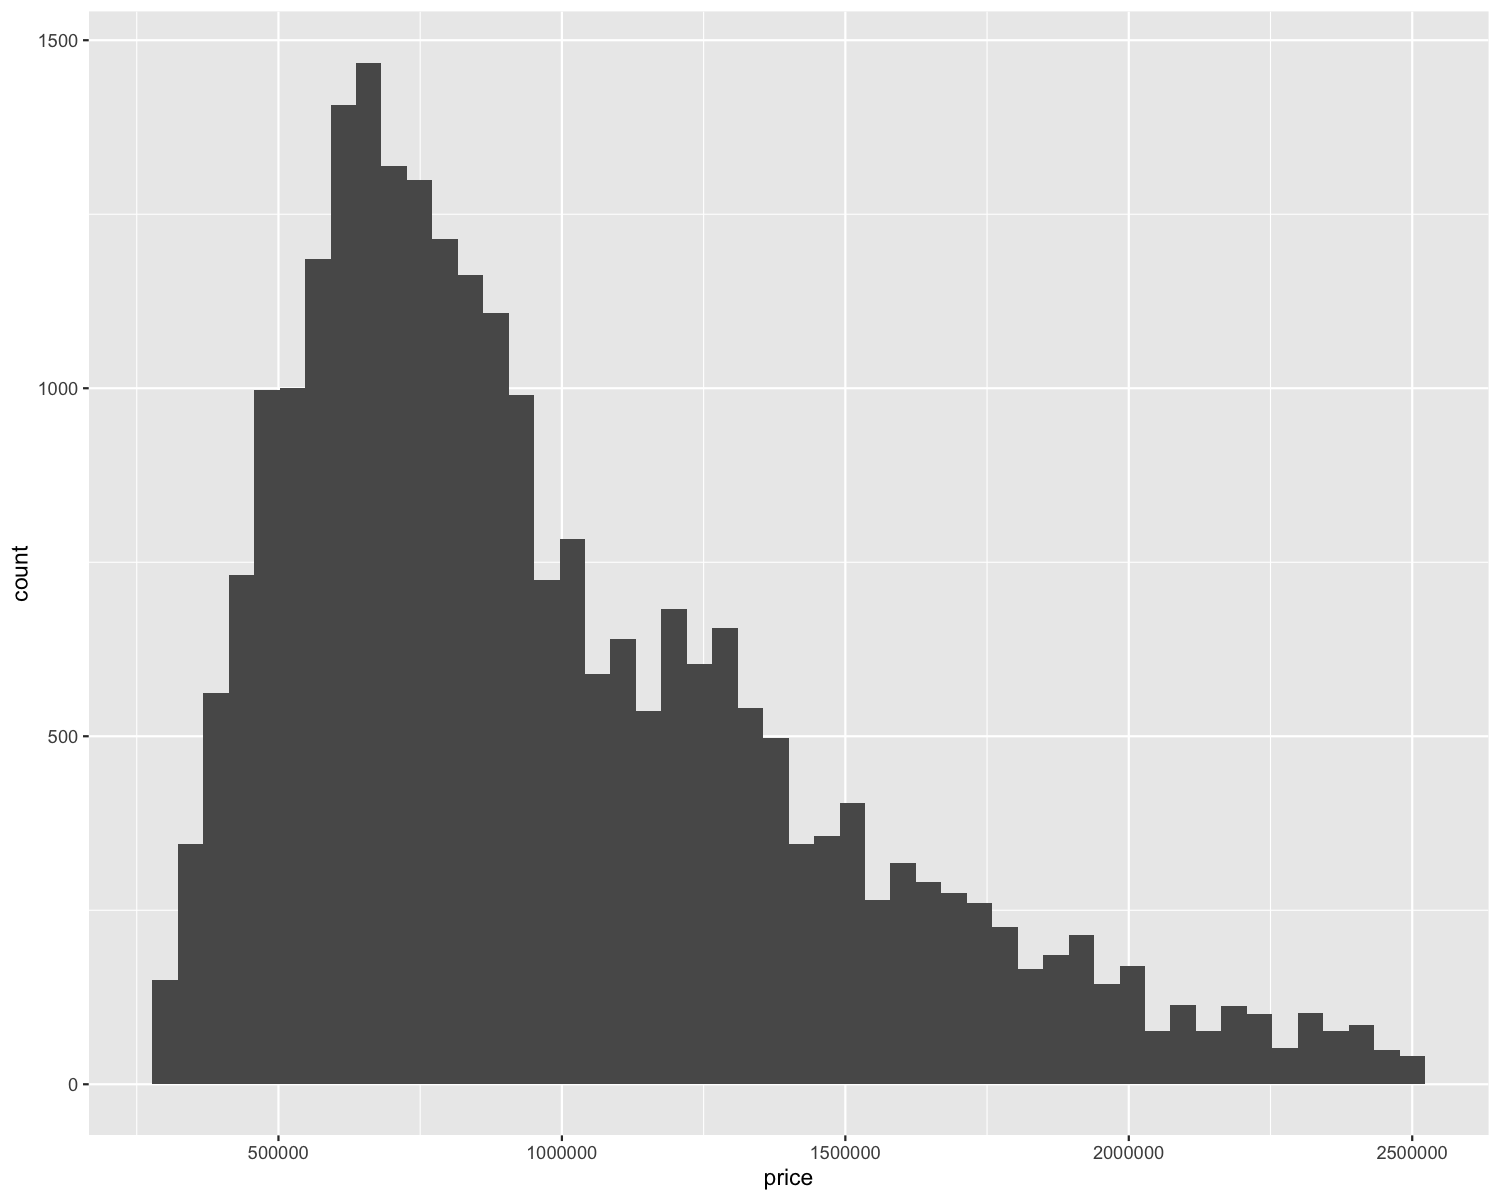

In [24]:
ggplot(housing, aes(x = price)) +
  geom_histogram(bins = 50)

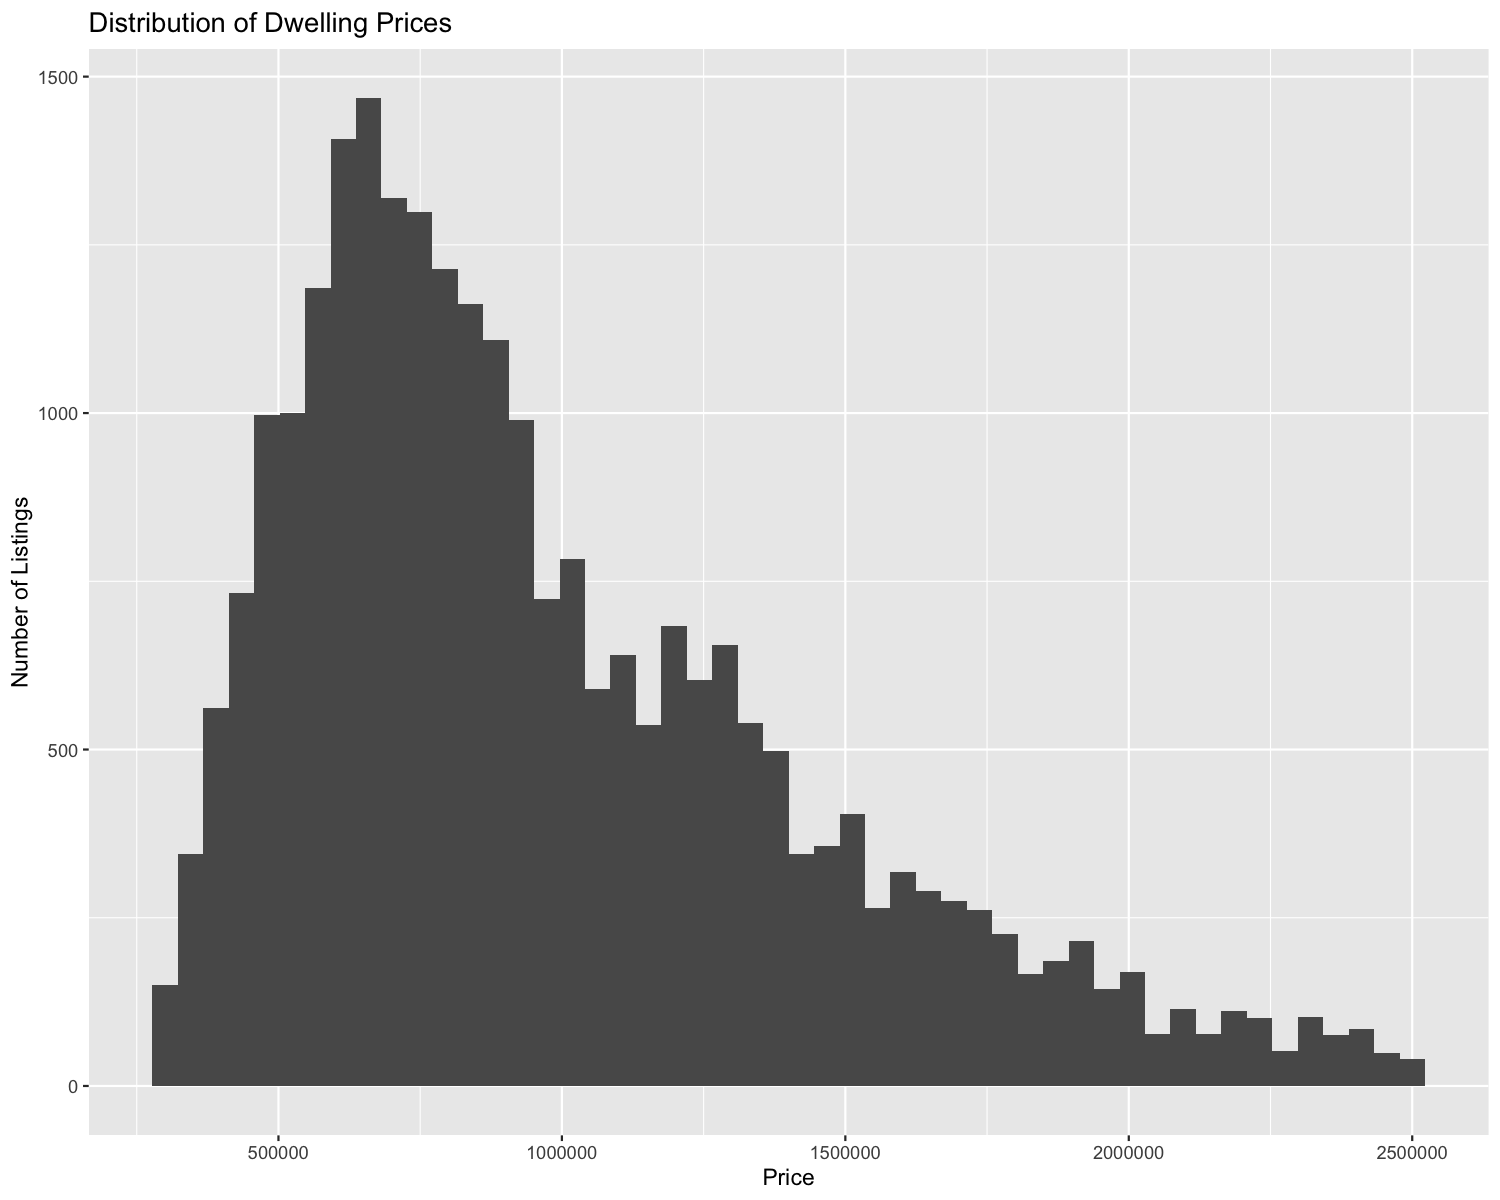

In [25]:
ggplot(housing, aes(x = price)) +
  geom_histogram(bins = 50) +
  labs(
    x = "Price", 
    y = "Number of Listings", 
    title = "Distribution of Dwelling Prices"
  )

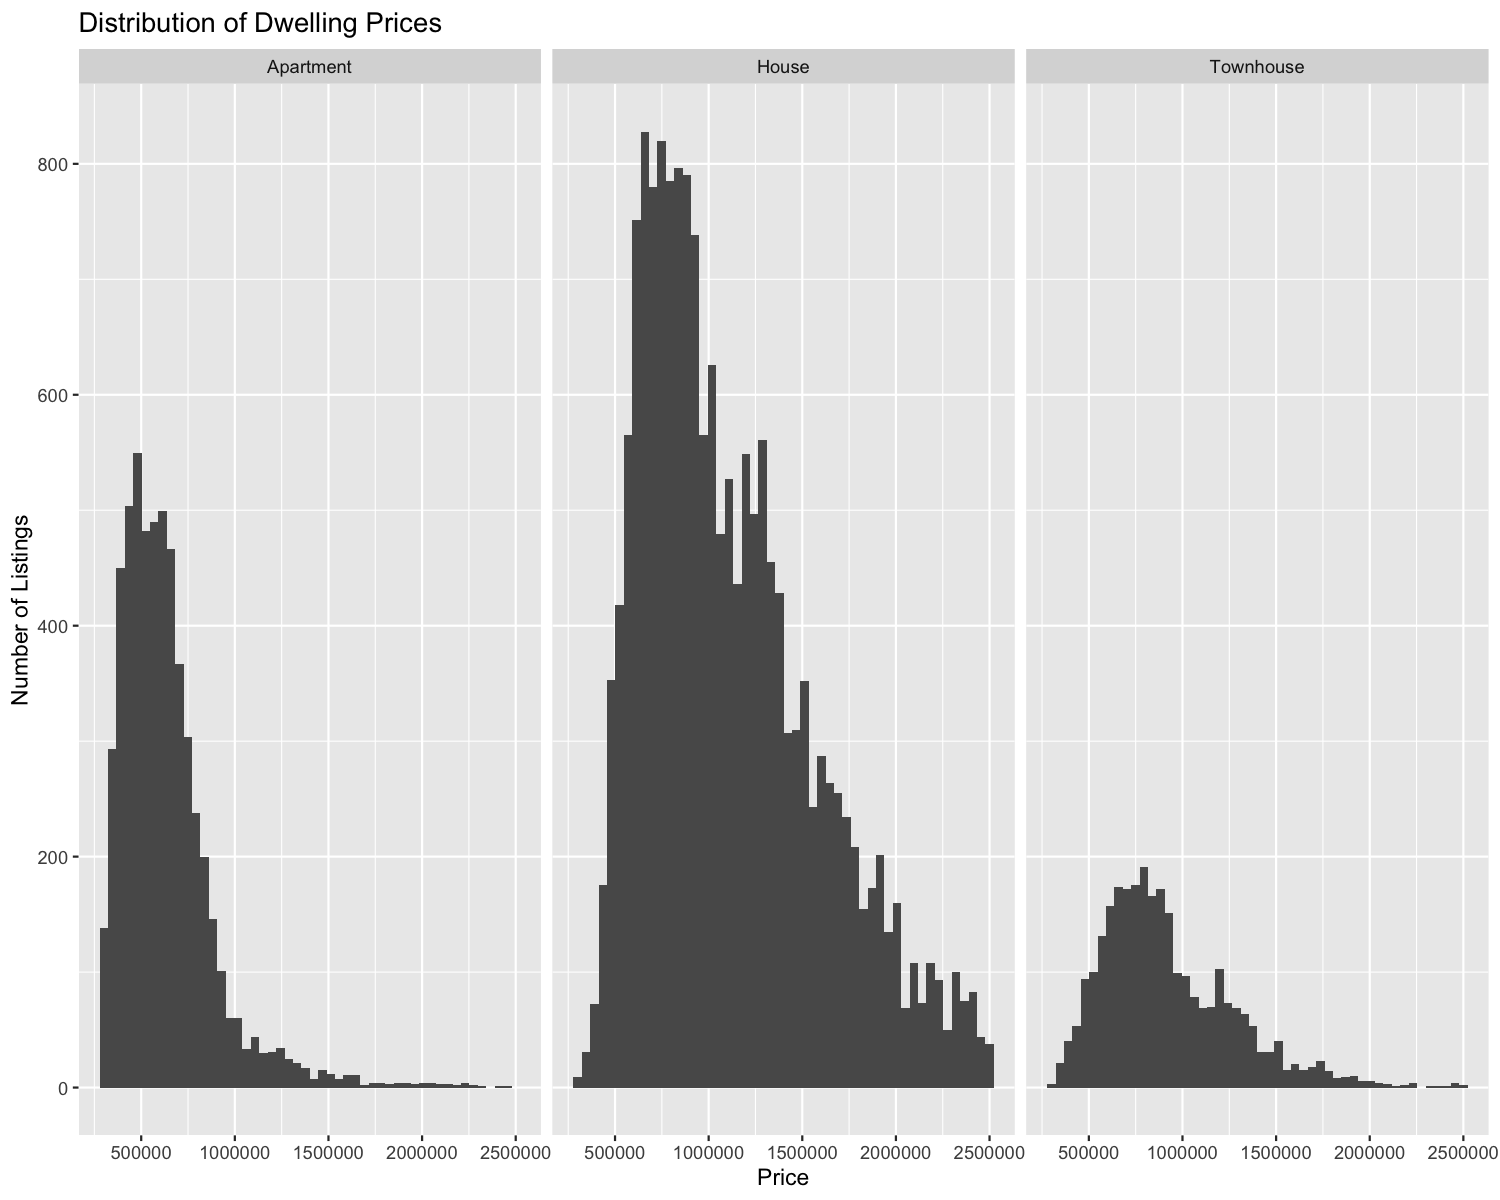

In [26]:
ggplot(housing, aes(x = price)) +
  geom_histogram(bins = 50) +
  labs(
    x = "Price", 
    y = "Number of Listings", 
    title = "Distribution of Dwelling Prices"
  ) +
  facet_wrap(~ type)

### Exercise 3

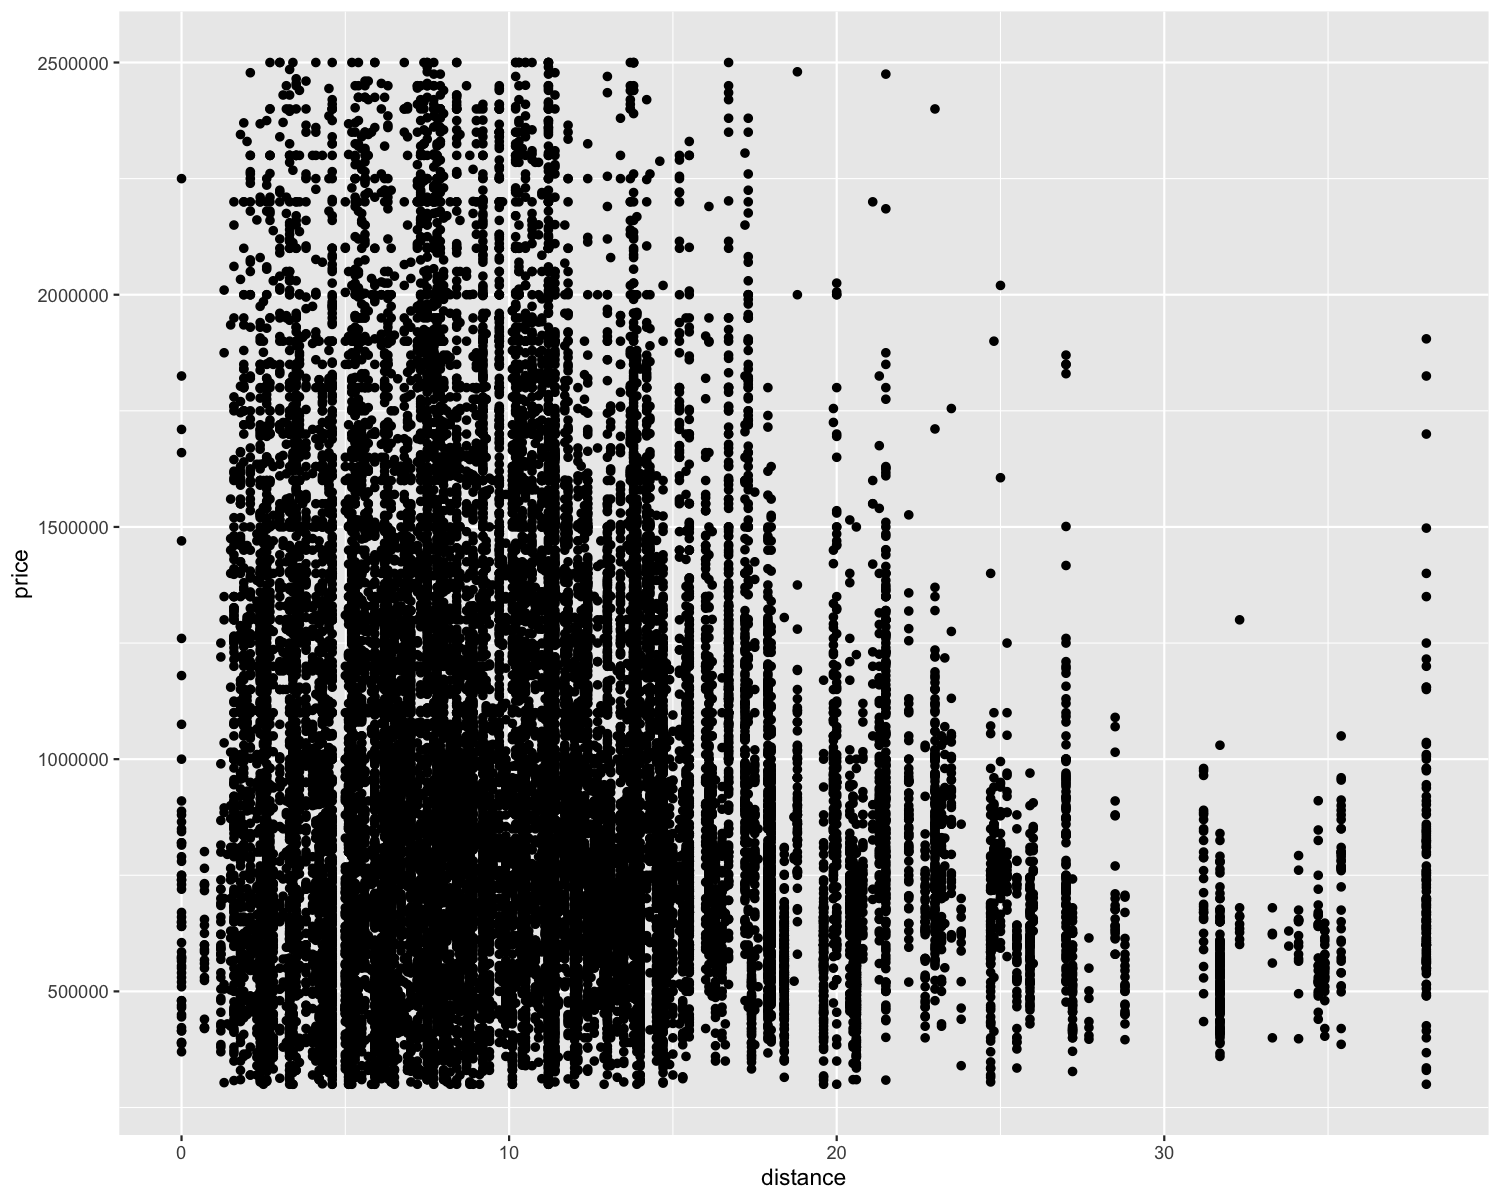

In [27]:
ggplot(housing, aes(x = distance, y = price)) +
  geom_point()

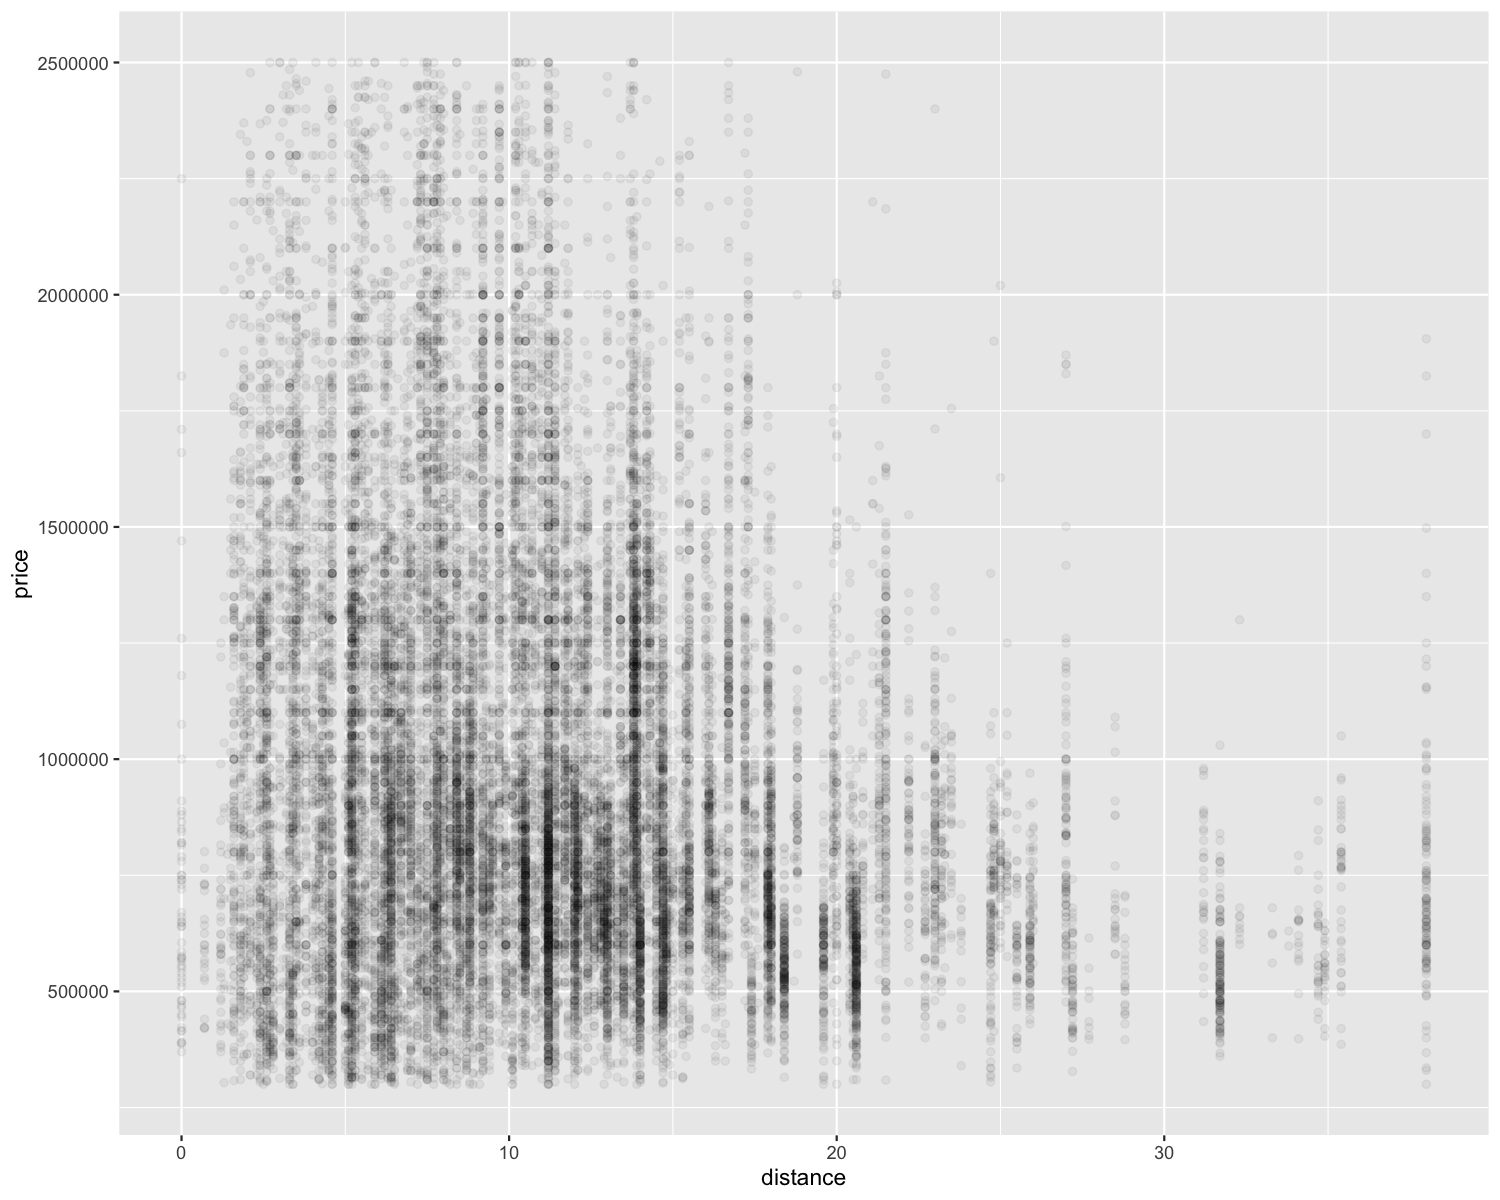

In [28]:
ggplot(housing, aes(x = distance, y = price)) +
  geom_point(alpha = 0.05)

`geom_smooth()` using formula = 'y ~ x'


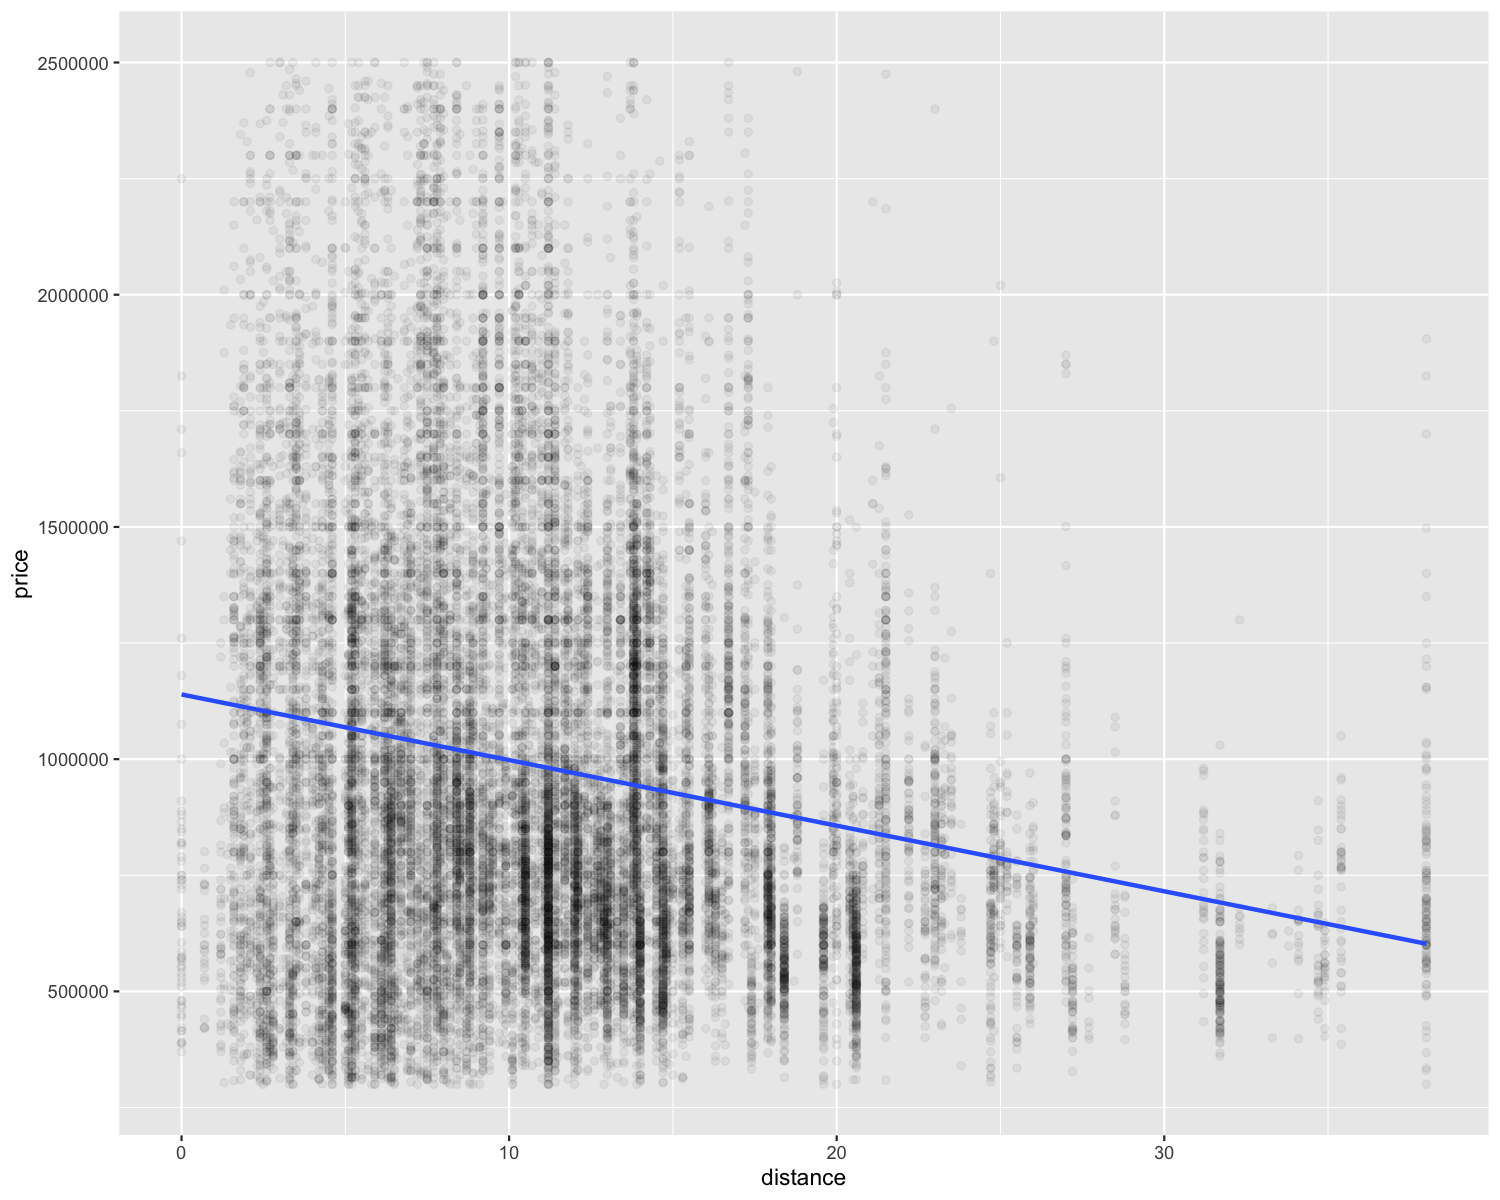

In [29]:
ggplot(housing, aes(x = distance, y = price)) +
  geom_point(alpha = 0.05) +
  geom_smooth(method = "lm", se = FALSE)

`geom_smooth()` using formula = 'y ~ x'


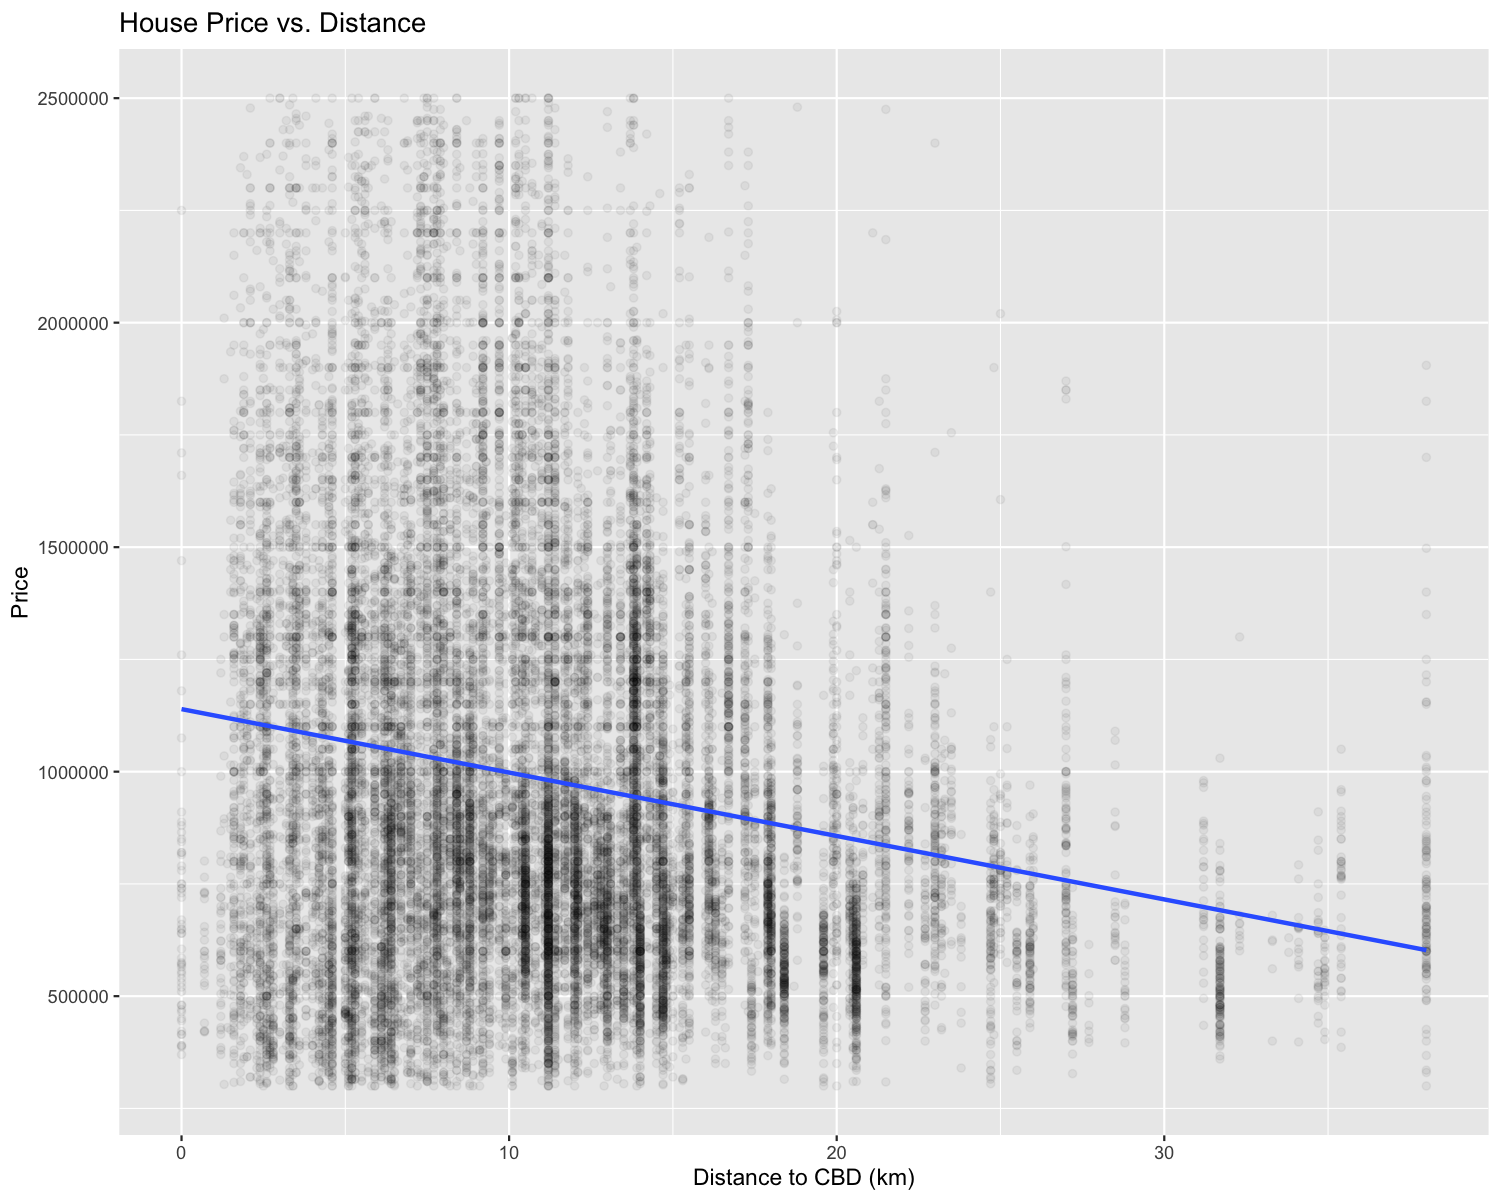

In [30]:
ggplot(housing, aes(x = distance, y = price)) +
  geom_point(alpha = 0.05) +
  geom_smooth(method = "lm", se = FALSE, linewidth = 1) +
  labs(
    x = "Distance to CBD (km)", 
    y = "Price", 
    title = "House Price vs. Distance"
  )

## In-Class Exercises

### Exercise 4: Improving the Price Distribution Plot

In [32]:
options(repr.plot.width = 12, repr.plot.height = 10, repr.plot.res = 150)

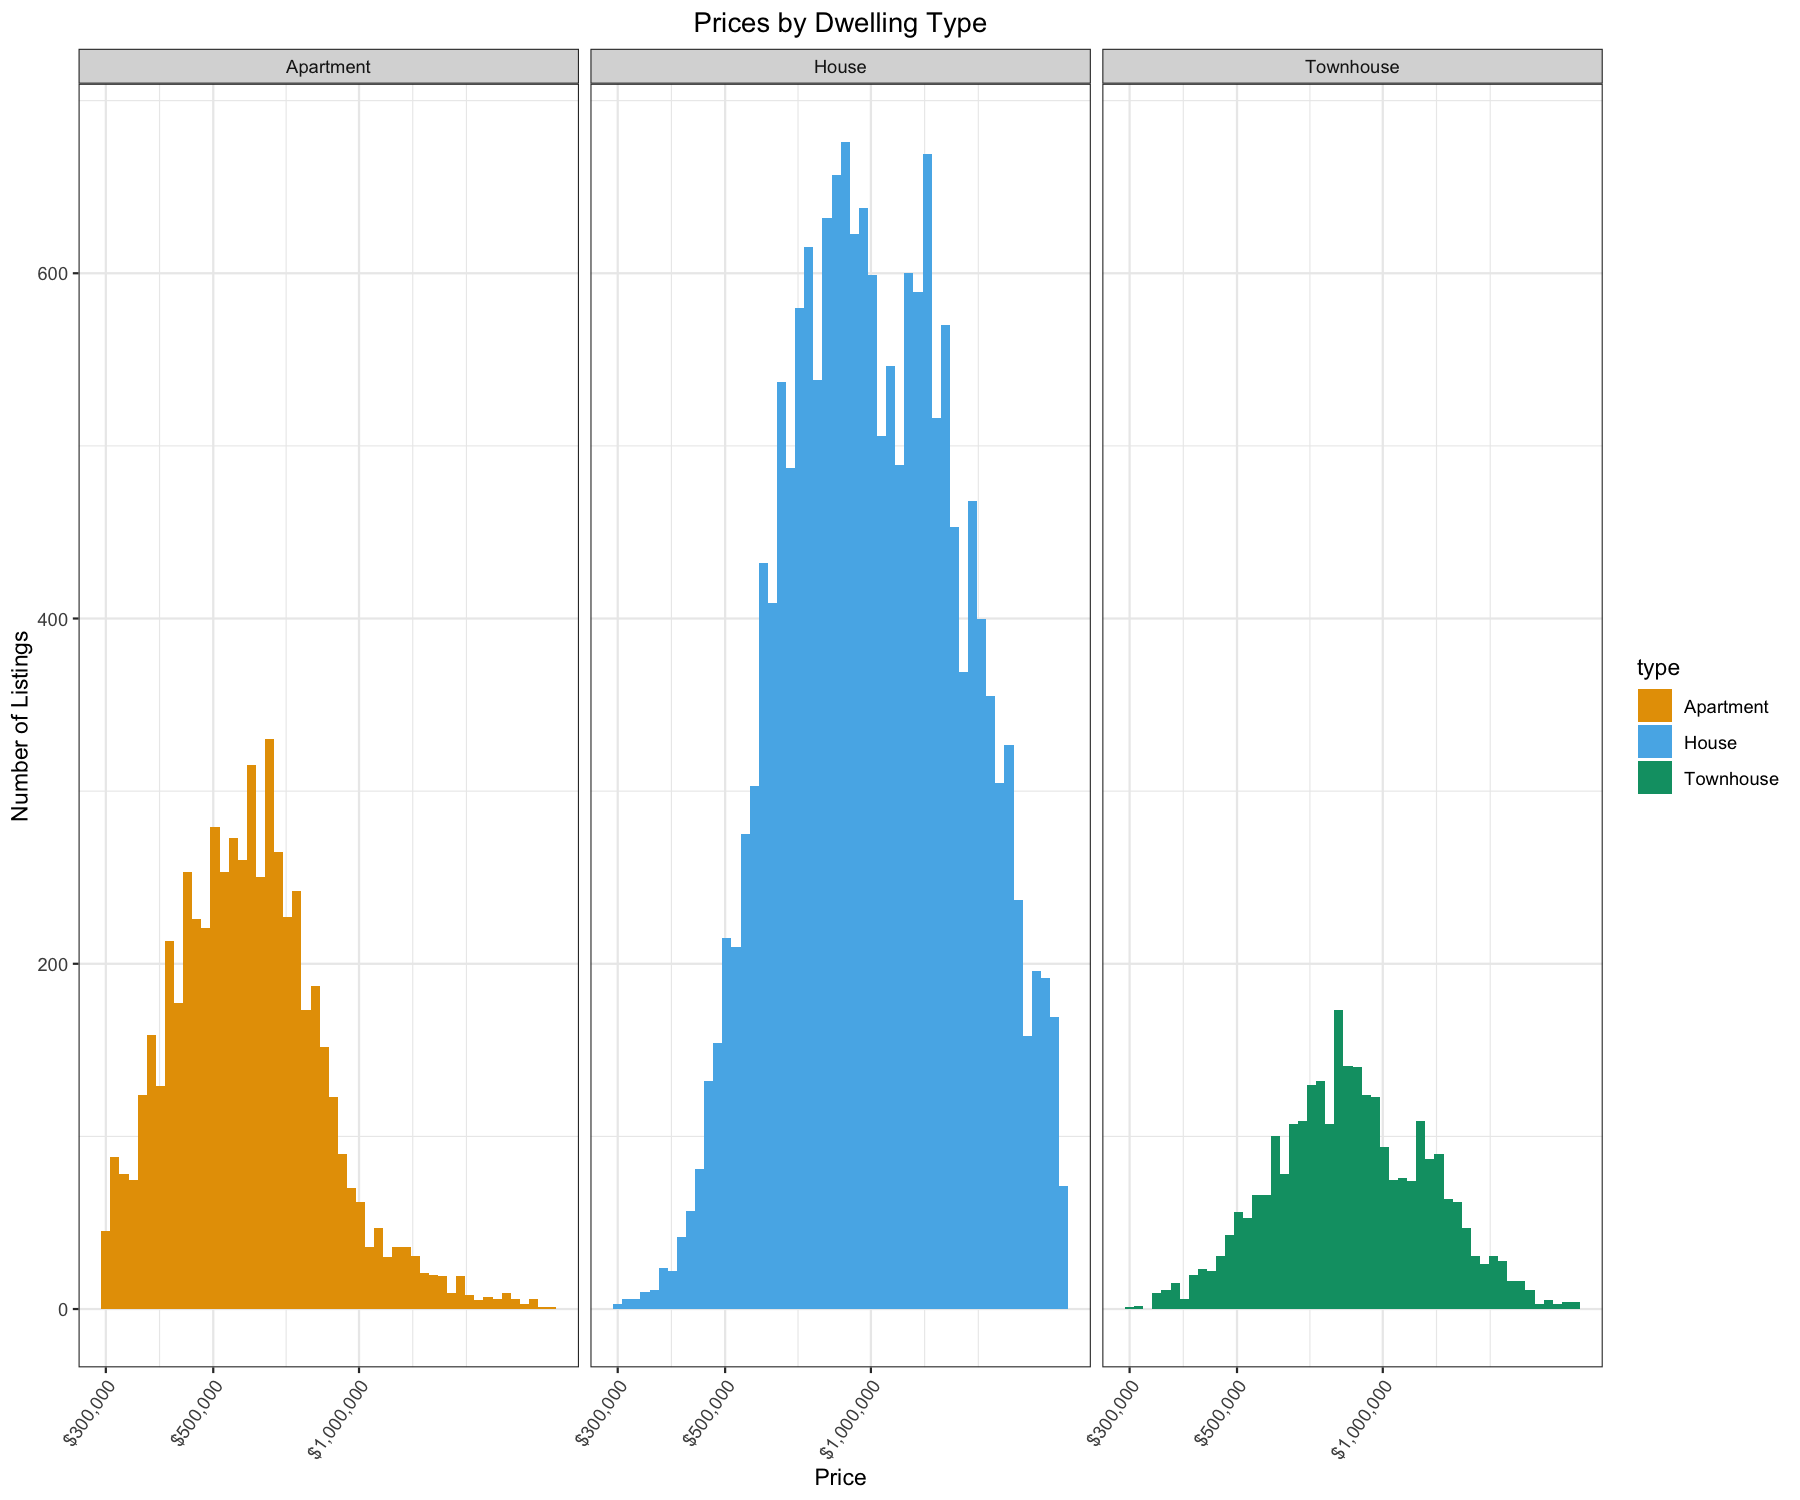

In [33]:
# Improved histogram of price by dwelling type
price_hist <- ggplot(housing, aes(x = price, fill = type)) +
  geom_histogram(bins = 50) +
  # Log-scale the x-axis to handle price skew
  scale_x_continuous(
    trans = "log10",
    labels = scales::dollar
  ) +
  # Add labels and title
  labs(
    x = "Price", 
    y = "Number of Listings", 
    title = "Prices by Dwelling Type"
  ) +
  # Create separate plots for each dwelling type
  facet_wrap(~type) +
  # Use colorblind-friendly fill palette
  scale_fill_okabe_ito() +
  theme_bw() +    # Rotate x-axis labels for readability
  theme(axis.text.x = element_text(angle = 55, hjust = 1)) +
  # Center the title
  theme(plot.title = element_text(hjust = 0.5))

price_hist

### Exercise 5

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'


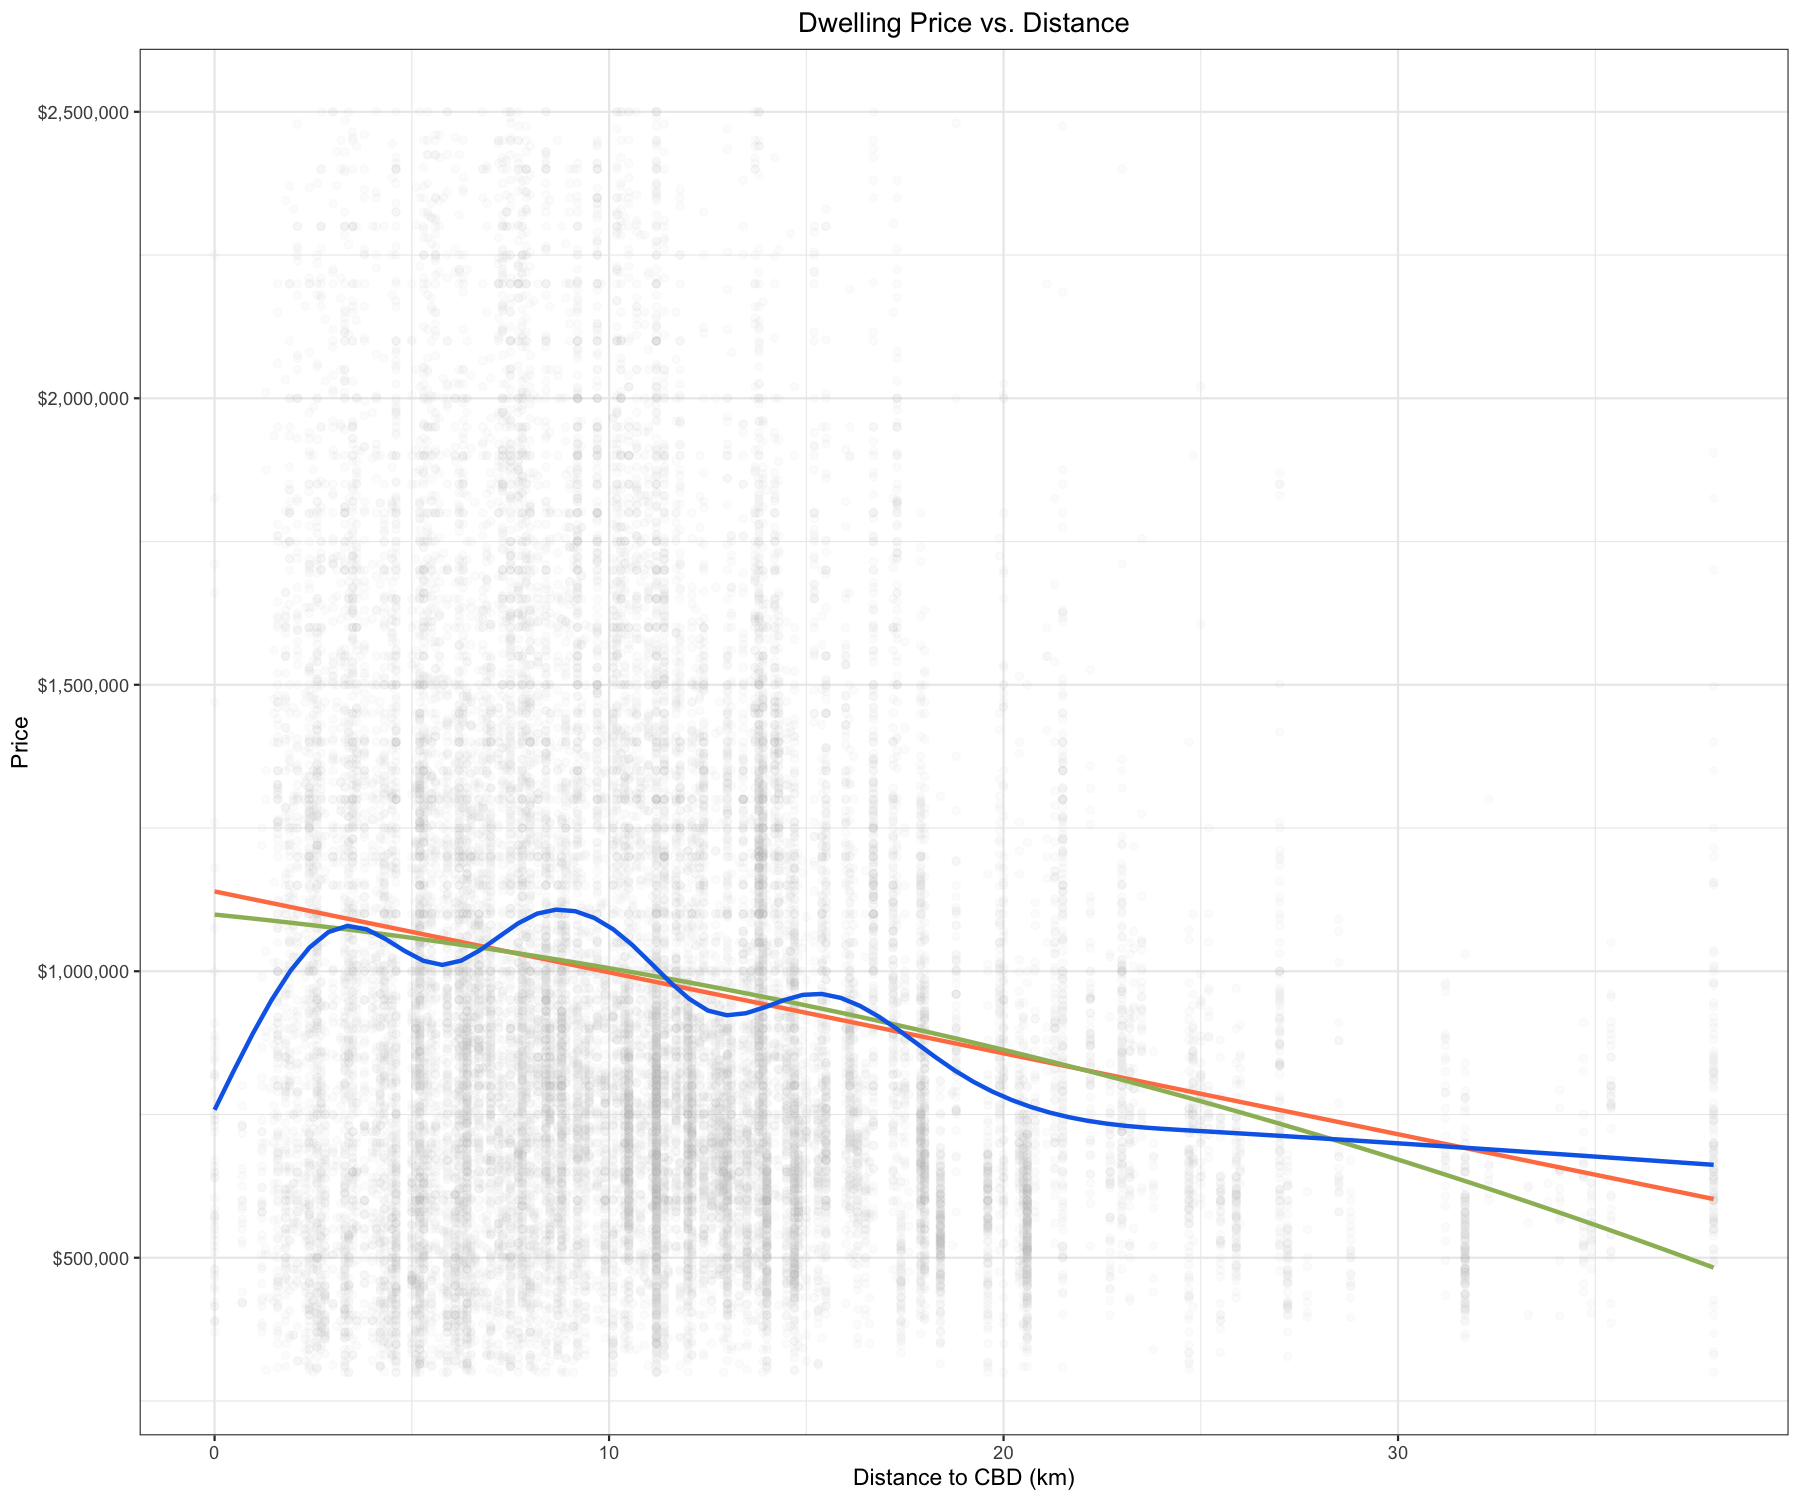

In [36]:
# Improved scatterplot: price vs. distance
scttr <- ggplot(housing, aes(x = distance, y = price)) +
  # Scatter plot with reduced alpha to handle overplotting
  geom_point(alpha = 0.05, color = "grey") +
  # Here's alternative lines we could use. Pick ONE.
  # 1. stay linear
  geom_smooth(
    method = "lm",
    se = FALSE,
    color = "coral",
    linewidth = 1
  ) +
  # 2. move to non-linear / quadratic "one bend" 
  geom_smooth(
      method = "lm",
      formula = y ~ poly(x, 2),   # Allow one bend in the trend line
      se = FALSE,
      color = "#9db964",
      linewidth = 1 
  ) +
  # 3. move to something non-parametric
  # The default is a 'loess' polynomial. "many bends"
  # inutuitively, think of this as using points in the close neighborhood of each other
  # to determine the 'local' slope of the line
  # note that local slope may violate notions of 'correct' theoretical direction of 
  # relationship
  geom_smooth(
      se = FALSE,
      color = "#0b6be9ff",
      linewidth = 1
  ) +
  # Format y-axis as dollars
  scale_y_continuous(labels = scales::dollar) +
  # Add labels and center the title
  labs(
    x = "Distance to CBD (km)",
    y = "Price",
    title = "Dwelling Price vs. Distance"
  ) +
  theme_bw() +
  theme(plot.title = element_text(hjust = 0.5)) 

scttr

### Exercise 6

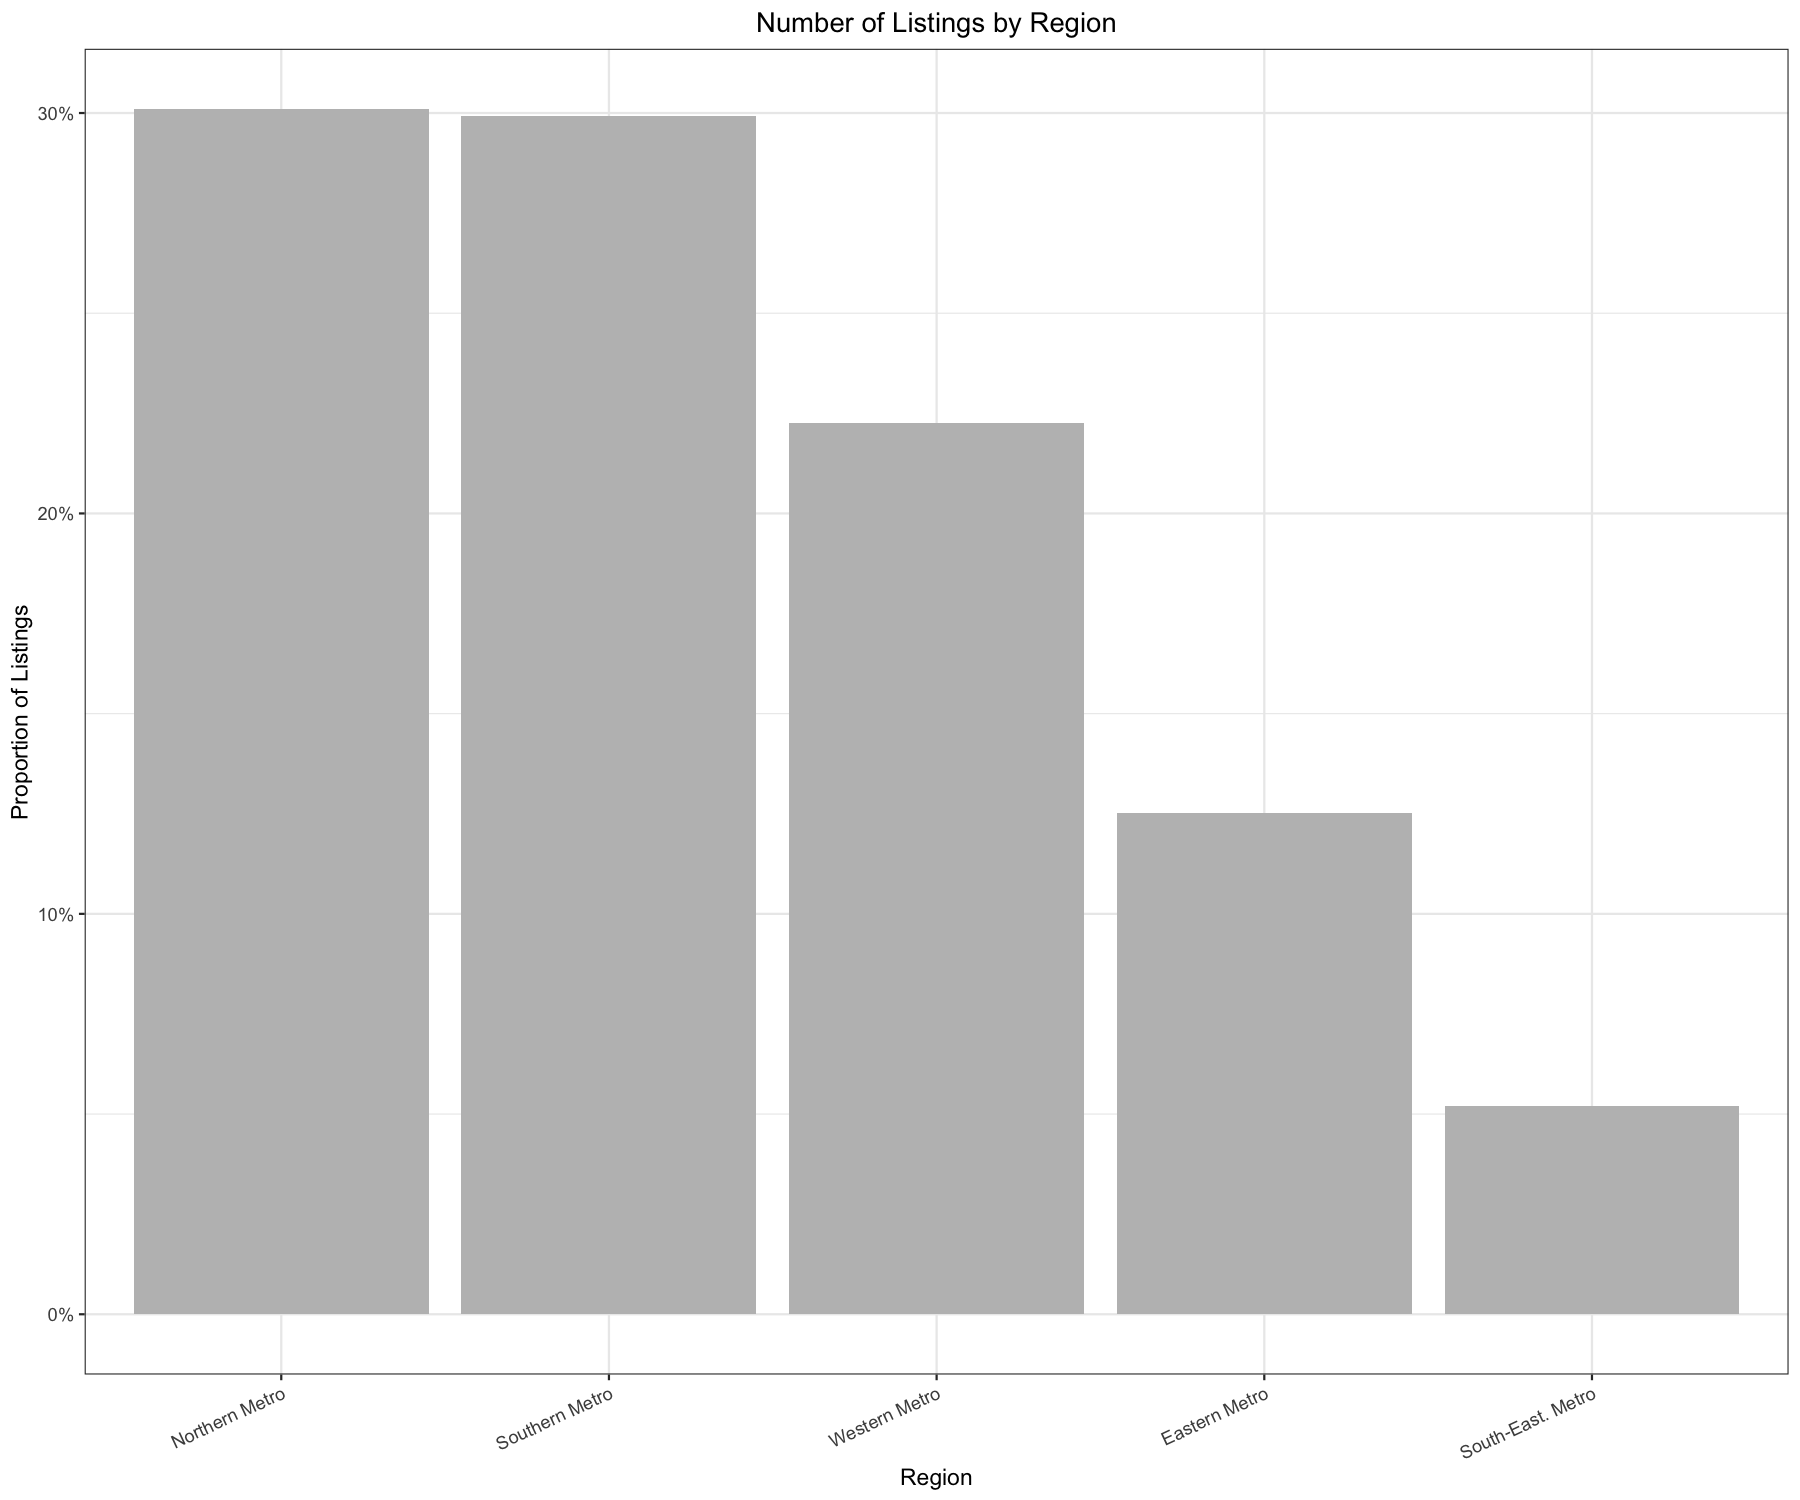

In [37]:
# Solution: use proportions, order bars, and center title
region_bar <- 
  # 2. Create the plot
  ggplot(
    housing,
    # 2a. Reorder the region names based on frequency
        aes(x = fct_infreq(regionname))
  ) +
  # 3. Plot bar heights as proportions, not raw counts
  geom_bar(
    # THIS BIT IS HARD
    # YOU CAN NOT USE IT AND KEEP Y AXIS AS COUNTS
    aes(y = after_stat(count) / sum(after_stat(count))),
    fill = "grey"
  ) +
  # 4. Add informative axis labels and a title
  labs(
    x = "Region", 
    y = "Proportion of Listings",  # Note: this is technically a proportion, not % format
    title = "Number of Listings by Region"
  ) +
  # 5. Tweak the theme for better readability and presentation
  scale_y_continuous(labels = scales::percent) +
  theme_bw() +
  theme(
    axis.text.x = element_text(angle = 25, hjust = 1),  # Rotate x labels
    plot.title = element_text(hjust = 0.5)              # Center the title
  )

region_bar

### Exercise 7

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'


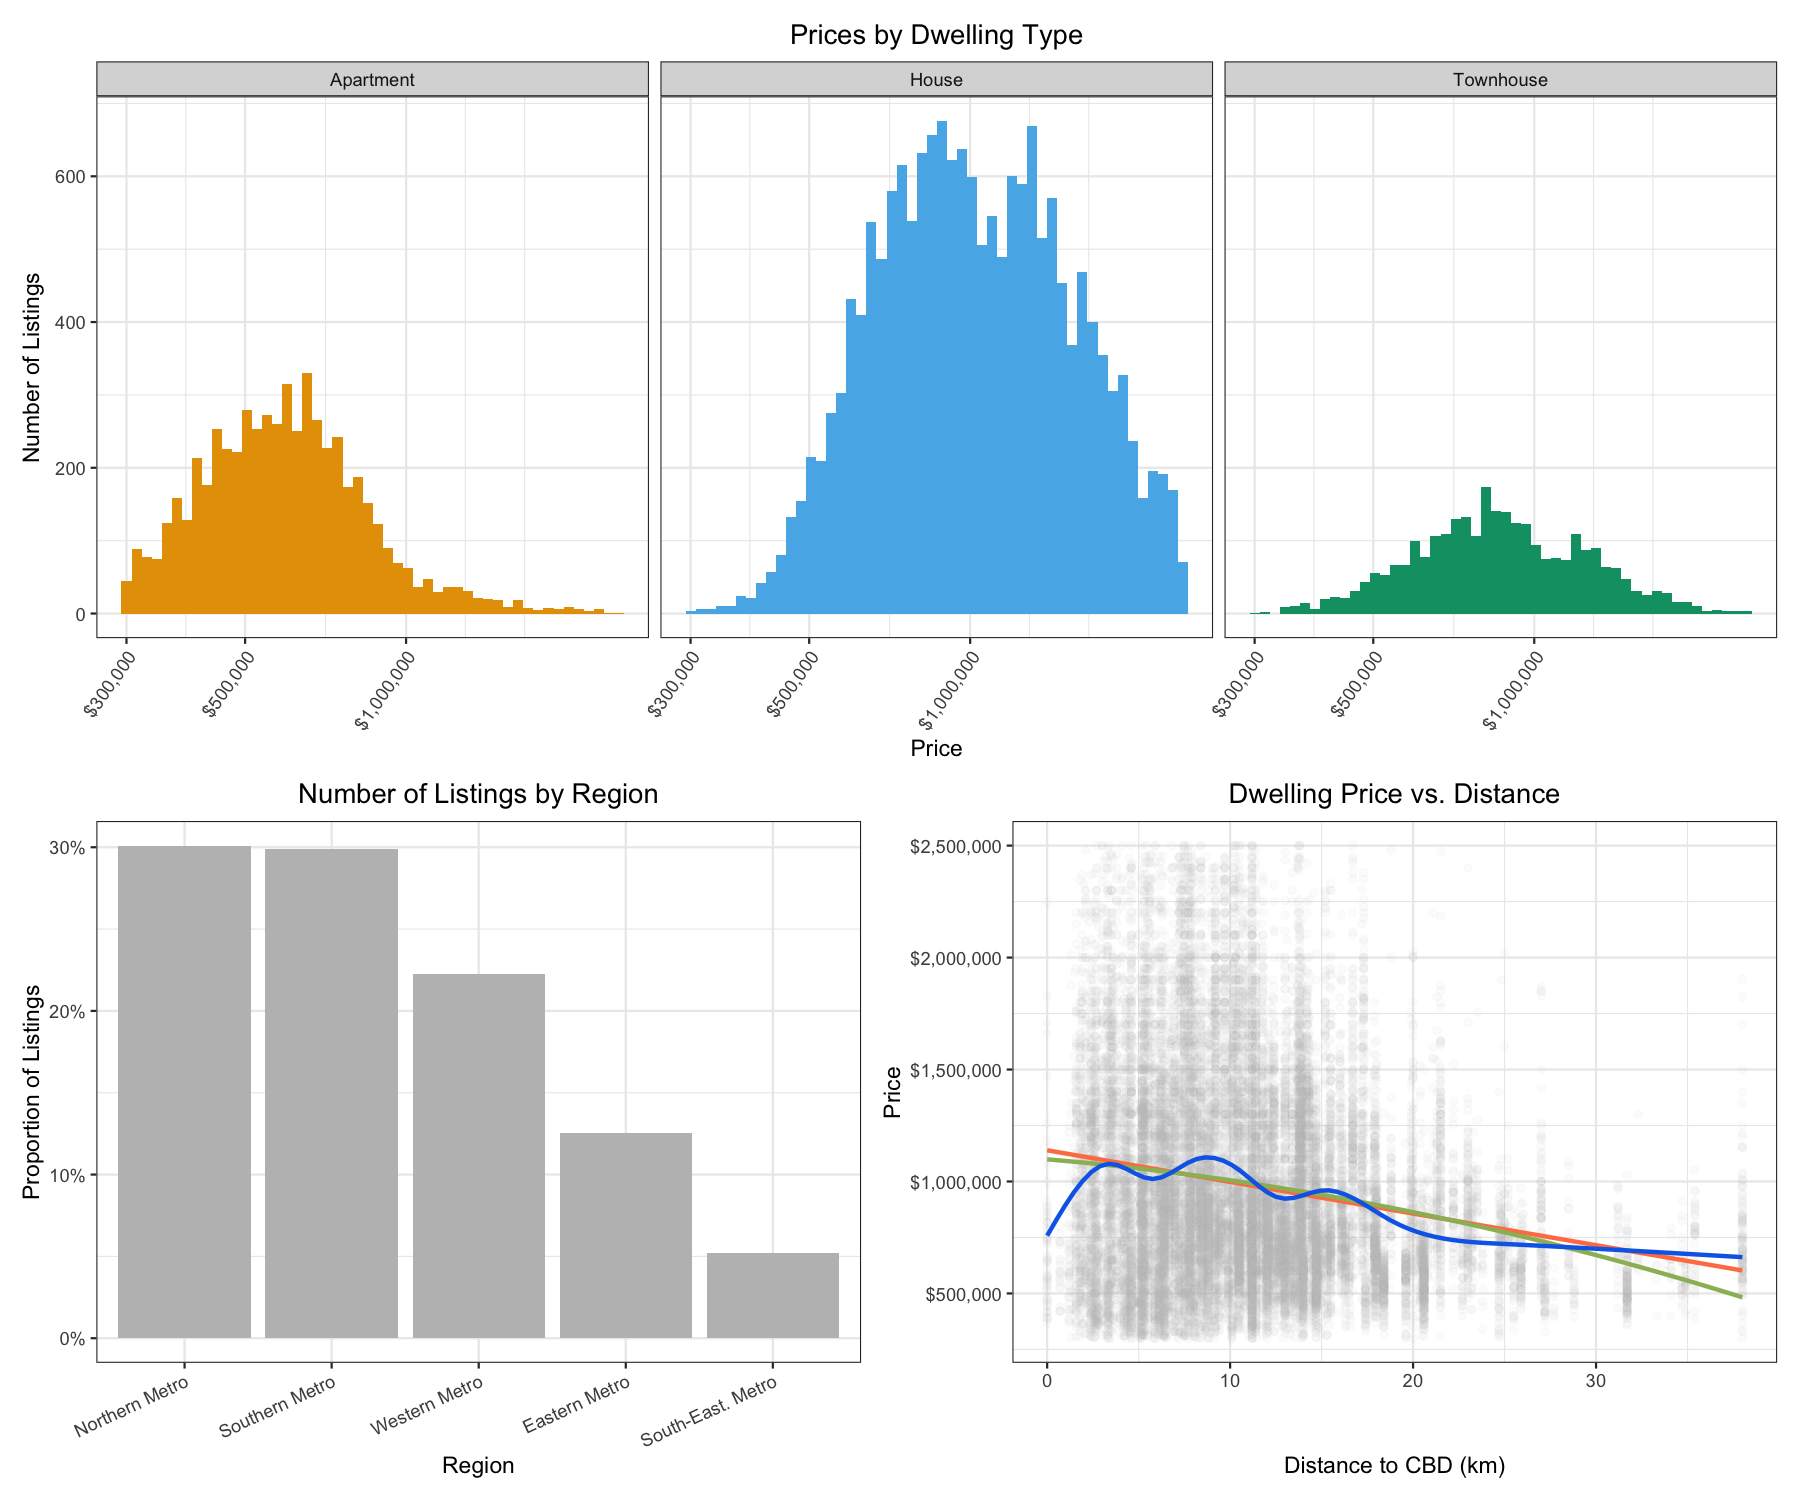

In [39]:
combined_plot <- 
  price_hist / 
  (region_bar | scttr) & 
  theme(legend.position = "none")

combined_plot